# EA-TTM — Horizon Performance Line Graphs

**Project:** Extreme-Aware Tiny Time Mixers (EA-TTM) for Retail Demand Forecasting under Regime Shifts  
**Phase:** 11B — Locked final-test horizon-wise visualization  
**Scope:** Create line graphs and horizon-level tables showing how each model performs across the 28-day locked forecast horizon.

No model is trained, modified, reselected, or reevaluated in this notebook.  
It only reads the locked final-test outputs written in Phase 10.

## Governance constraint

Phase 10 sealed the final evaluation:

$$
\text{Post-test tuning} = \text{False}.
$$

Therefore this notebook may only summarize already-saved predictions and errors. It may not alter any model, threshold, feature definition, or checkpoint selection.

## Horizon-level metrics

For each horizon step \(h \in \{1,\dots,28\}\), the notebook computes:

$$
\mathrm{MSE}_h
=
\frac{1}{N}
\sum_{i=1}^{N}
(y_{i,h}-\hat y_{i,h})^2,
$$

$$
\mathrm{RMSE}_h
=
\sqrt{\mathrm{MSE}_h},
$$

$$
\mathrm{MAE}_h
=
\frac{1}{N}
\sum_{i=1}^{N}
|y_{i,h}-\hat y_{i,h}|,
$$

and

$$
\mathrm{WAPE}_h
=
\frac{
\sum_{i=1}^{N}|y_{i,h}-\hat y_{i,h}|
}{
\sum_{i=1}^{N}|y_{i,h}|
}.
$$

The same logic is applied to regime-specific subsets, including normal observations, all extremes, positive extremes, and negative extremes.

## Comparison focus

The most important line graphs are:

1. overall horizon-wise MSE for all locked comparison models;
2. overall horizon-wise MAE for all locked comparison models;
3. overall horizon-wise WAPE for all locked comparison models;
4. primary EA-TTM versus frozen HP-TTM percentage improvement in MSE by horizon;
5. primary EA-TTM versus frozen HP-TTM percentage improvement in extreme MSE by horizon;
6. extreme prevalence by horizon, so the reader can interpret the error curves in context.

In [1]:
from __future__ import annotations

import json
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Project preflight

In [2]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/EA_TTM_RETAIL")
METADATA_DIR = PROJECT_ROOT / "metadata"
RESULTS_TABLE_DIR = PROJECT_ROOT / "results" / "tables"
RESULTS_FIGURE_DIR = PROJECT_ROOT / "results" / "figures"
PHASE10_RUN_DIR = PROJECT_ROOT / "runs" / "10_locked_final_test"

RESULTS_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

required_artifacts = {
    "phase10_summary": METADATA_DIR / "10_RUN_SUMMARY.json",
    "development_lock": METADATA_DIR / "09_MODEL_DEVELOPMENT_LOCK.json",
    "final_evaluation_lock": METADATA_DIR / "10_FINAL_EVALUATION_LOCK.json",
    "final_test_outputs": PHASE10_RUN_DIR / "10_FINAL_TEST_OUTPUTS.npz",
}

missing = [
    str(path)
    for path in required_artifacts.values()
    if not path.exists()
]

assert not missing, (
    "Phase 11B prerequisites are incomplete: "
    + "; ".join(missing)
)

Mounted at /content/drive


## Load locked experiment state

In [3]:
def load_json(path: Path) -> dict[str, Any]:
    return json.loads(
        path.read_text(
            encoding="utf-8"
        )
    )

phase10 = load_json(
    METADATA_DIR / "10_RUN_SUMMARY.json"
)

development_lock = load_json(
    METADATA_DIR / "09_MODEL_DEVELOPMENT_LOCK.json"
)

final_evaluation_lock = load_json(
    METADATA_DIR / "10_FINAL_EVALUATION_LOCK.json"
)

assert development_lock["post_lock_tuning_permitted"] is False
assert final_evaluation_lock["post_test_tuning_permitted"] is False
assert final_evaluation_lock["test_results_may_change_model_selection"] is False

PRIMARY_MODEL = development_lock["primary_model"]
PRIMARY_EPOCH = int(
    development_lock["primary_epoch"]
)

assert PRIMARY_MODEL == "Phase 08 best-balanced EA-TTM"
assert PRIMARY_EPOCH == 15

print("Primary model:", PRIMARY_MODEL)
print("Primary epoch:", PRIMARY_EPOCH)
print("Final-test interval:", final_evaluation_lock["final_test_interval"])

Primary model: Phase 08 best-balanced EA-TTM
Primary epoch: 15
Final-test interval: ['d_1914', 'd_1941']


## Load locked final-test outputs

In [4]:
output_bundle = np.load(
    PHASE10_RUN_DIR / "10_FINAL_TEST_OUTPUTS.npz"
)

actual = output_bundle["actual"]

model_arrays = {
    "Weekly Seasonal Naive": output_bundle["seasonal_naive"],
    "Zero-shot TTM": output_bundle["zero_shot_ttm"],
    "Frozen HP-TTM": output_bundle["hp_ttm"],
    "Retail-only gated adapter": output_bundle["retail_only_gated"],
    "Ungated cross-feed adapter": output_bundle["ungated_crossfeed"],
    "Primary EA-TTM": output_bundle["primary_ea_ttm"],
}

extreme_label = output_bundle["extreme_label"].astype(bool)
positive_extreme = output_bundle["positive_extreme"].astype(bool)
negative_extreme = output_bundle["negative_extreme"].astype(bool)
normal_label = ~extreme_label

SERIES_COUNT, HORIZON = actual.shape

assert SERIES_COUNT == 30490
assert HORIZON == 28

horizon_index = np.arange(1, HORIZON + 1)
day_labels = [f"d_{1913 + h}" for h in horizon_index]

print("Series count:", SERIES_COUNT)
print("Forecast horizon:", HORIZON)

Series count: 30490
Forecast horizon: 28


## Horizon-level metric utilities

In [5]:
def horizon_metrics(
    actual_array: np.ndarray,
    predicted_array: np.ndarray,
) -> pd.DataFrame:
    error = predicted_array.astype(np.float64) - actual_array.astype(np.float64)
    abs_error = np.abs(error)
    sq_error = np.square(error)

    mse = sq_error.mean(axis=0)
    rmse = np.sqrt(mse)
    mae = abs_error.mean(axis=0)
    wape = abs_error.sum(axis=0) / np.abs(actual_array.astype(np.float64)).sum(axis=0)

    return pd.DataFrame(
        {
            "horizon": horizon_index,
            "day_label": day_labels,
            "mse": mse,
            "rmse": rmse,
            "mae": mae,
            "wape": wape,
        }
    )

def masked_horizon_mse(
    actual_array: np.ndarray,
    predicted_array: np.ndarray,
    mask_array: np.ndarray,
) -> np.ndarray:
    result = np.full(
        HORIZON,
        np.nan,
        dtype=np.float64,
    )

    error = predicted_array.astype(np.float64) - actual_array.astype(np.float64)
    sq_error = np.square(error)

    for h in range(HORIZON):
        horizon_mask = mask_array[:, h]
        if horizon_mask.any():
            result[h] = sq_error[horizon_mask, h].mean()

    return result

## Build the horizon-level results table

In [6]:
horizon_frames = []

extreme_count = extreme_label.sum(axis=0).astype(int)
positive_extreme_count = positive_extreme.sum(axis=0).astype(int)
negative_extreme_count = negative_extreme.sum(axis=0).astype(int)
normal_count = normal_label.sum(axis=0).astype(int)

for model_name, prediction_array in model_arrays.items():
    base_frame = horizon_metrics(
        actual,
        prediction_array,
    )

    base_frame["model"] = model_name
    base_frame["normal_mse"] = masked_horizon_mse(
        actual,
        prediction_array,
        normal_label,
    )
    base_frame["extreme_mse"] = masked_horizon_mse(
        actual,
        prediction_array,
        extreme_label,
    )
    base_frame["positive_extreme_mse"] = masked_horizon_mse(
        actual,
        prediction_array,
        positive_extreme,
    )
    base_frame["negative_extreme_mse"] = masked_horizon_mse(
        actual,
        prediction_array,
        negative_extreme,
    )
    base_frame["normal_count"] = normal_count
    base_frame["extreme_count"] = extreme_count
    base_frame["positive_extreme_count"] = positive_extreme_count
    base_frame["negative_extreme_count"] = negative_extreme_count
    base_frame["extreme_rate"] = extreme_count / SERIES_COUNT
    base_frame["positive_extreme_rate"] = positive_extreme_count / SERIES_COUNT
    base_frame["negative_extreme_rate"] = negative_extreme_count / SERIES_COUNT

    horizon_frames.append(base_frame)

horizon_results = pd.concat(
    horizon_frames,
    axis=0,
    ignore_index=True,
)

HORIZON_RESULTS_PATH = (
    RESULTS_TABLE_DIR
    / "11B_FINAL_TEST_HORIZON_METRICS.csv"
)

horizon_results.to_csv(
    HORIZON_RESULTS_PATH,
    index=False,
)

horizon_results.head()

,horizon,day_label,mse,rmse,mae,wape,model,normal_mse,extreme_mse,positive_extreme_mse,negative_extreme_mse,normal_count,extreme_count,positive_extreme_count,negative_extreme_count,extreme_rate,positive_extreme_rate,negative_extreme_rate
0,1,d_1914,6.969761,2.640030,1.162086,0.913361,Weekly Seasonal Naive,5.104706,48.414318,50.402490,26.231481,29177,1313,1205,108,0.043063,0.039521,0.003542
1,2,d_1915,5.175041,2.274872,1.096523,0.942120,Weekly Seasonal Naive,4.013708,34.433849,35.202358,29.075342,29326,1164,1018,146,0.038176,0.033388,0.004788
2,3,d_1916,5.133290,2.265676,1.063627,0.941501,Weekly Seasonal Naive,3.642348,42.932584,47.038961,16.583333,29333,1157,1001,156,0.037947,0.032830,0.005116
3,4,d_1917,5.060840,2.249631,1.061233,0.931619,Weekly Seasonal Naive,3.709996,38.408593,40.406160,24.385135,29303,1187,1039,148,0.038931,0.034077,0.004854
4,5,d_1918,5.816104,2.411660,1.174975,0.835159,Weekly Seasonal Naive,3.919086,41.043646,41.277018,37.489583,28932,1558,1462,96,0.051099,0.047950,0.003149


## Primary EA-TTM versus frozen HP-TTM by horizon

In [7]:
ea_horizon = horizon_results.loc[
    horizon_results["model"] == "Primary EA-TTM"
].reset_index(drop=True)

hp_horizon = horizon_results.loc[
    horizon_results["model"] == "Frozen HP-TTM"
].reset_index(drop=True)

primary_vs_hp_horizon = pd.DataFrame(
    {
        "horizon": horizon_index,
        "day_label": day_labels,
        "hp_mse": hp_horizon["mse"].to_numpy(),
        "ea_mse": ea_horizon["mse"].to_numpy(),
        "hp_mae": hp_horizon["mae"].to_numpy(),
        "ea_mae": ea_horizon["mae"].to_numpy(),
        "hp_wape": hp_horizon["wape"].to_numpy(),
        "ea_wape": ea_horizon["wape"].to_numpy(),
        "hp_extreme_mse": hp_horizon["extreme_mse"].to_numpy(),
        "ea_extreme_mse": ea_horizon["extreme_mse"].to_numpy(),
        "hp_positive_extreme_mse": hp_horizon["positive_extreme_mse"].to_numpy(),
        "ea_positive_extreme_mse": ea_horizon["positive_extreme_mse"].to_numpy(),
        "hp_negative_extreme_mse": hp_horizon["negative_extreme_mse"].to_numpy(),
        "ea_negative_extreme_mse": ea_horizon["negative_extreme_mse"].to_numpy(),
        "extreme_count": extreme_count,
        "positive_extreme_count": positive_extreme_count,
        "negative_extreme_count": negative_extreme_count,
    }
)

primary_vs_hp_horizon["mse_improvement_percent"] = (
    100.0
    * (
        primary_vs_hp_horizon["hp_mse"]
        - primary_vs_hp_horizon["ea_mse"]
    )
    / primary_vs_hp_horizon["hp_mse"]
)

primary_vs_hp_horizon["mae_improvement_percent"] = (
    100.0
    * (
        primary_vs_hp_horizon["hp_mae"]
        - primary_vs_hp_horizon["ea_mae"]
    )
    / primary_vs_hp_horizon["hp_mae"]
)

primary_vs_hp_horizon["wape_improvement_percent"] = (
    100.0
    * (
        primary_vs_hp_horizon["hp_wape"]
        - primary_vs_hp_horizon["ea_wape"]
    )
    / primary_vs_hp_horizon["hp_wape"]
)

primary_vs_hp_horizon["extreme_mse_improvement_percent"] = (
    100.0
    * (
        primary_vs_hp_horizon["hp_extreme_mse"]
        - primary_vs_hp_horizon["ea_extreme_mse"]
    )
    / primary_vs_hp_horizon["hp_extreme_mse"]
)

primary_vs_hp_horizon["positive_extreme_mse_improvement_percent"] = (
    100.0
    * (
        primary_vs_hp_horizon["hp_positive_extreme_mse"]
        - primary_vs_hp_horizon["ea_positive_extreme_mse"]
    )
    / primary_vs_hp_horizon["hp_positive_extreme_mse"]
)

primary_vs_hp_horizon["negative_extreme_mse_improvement_percent"] = (
    100.0
    * (
        primary_vs_hp_horizon["hp_negative_extreme_mse"]
        - primary_vs_hp_horizon["ea_negative_extreme_mse"]
    )
    / primary_vs_hp_horizon["hp_negative_extreme_mse"]
)

PRIMARY_VS_HP_PATH = (
    RESULTS_TABLE_DIR
    / "11B_PRIMARY_VS_HP_HORIZON_COMPARISON.csv"
)

primary_vs_hp_horizon.to_csv(
    PRIMARY_VS_HP_PATH,
    index=False,
)

primary_vs_hp_horizon.head()

,horizon,day_label,hp_mse,ea_mse,hp_mae,ea_mae,hp_wape,ea_wape,hp_extreme_mse,ea_extreme_mse,...,ea_negative_extreme_mse,extreme_count,positive_extreme_count,negative_extreme_count,mse_improvement_percent,mae_improvement_percent,wape_improvement_percent,extreme_mse_improvement_percent,positive_extreme_mse_improvement_percent,negative_extreme_mse_improvement_percent
0,1,d_1914,3.443707,3.430536,0.933010,0.936734,0.733314,0.736242,37.123165,37.061216,...,23.064991,1313,1205,108,0.382468,-0.399198,-0.399198,0.166874,0.031449,2.612142
1,2,d_1915,2.714894,2.710110,0.865754,0.870785,0.743846,0.748168,27.794477,27.756122,...,27.899196,1164,1018,146,0.176192,-0.581029,-0.581029,0.137994,-0.040175,1.355777
2,3,d_1916,3.043594,3.037164,0.880966,0.886688,0.779813,0.784878,36.732569,36.483866,...,20.373739,1157,1001,156,0.211244,-0.649517,-0.649517,0.677064,0.643545,1.086888
3,4,d_1917,2.970022,2.961768,0.872078,0.877501,0.765567,0.770327,36.111950,35.818534,...,26.356579,1187,1039,148,0.277896,-0.621837,-0.621837,0.812519,0.844103,0.498760
4,5,d_1918,3.765490,3.741933,0.961615,0.967761,0.683505,0.687874,41.035636,40.511957,...,27.040945,1558,1462,96,0.625608,-0.639160,-0.639160,1.276156,1.390572,-1.468703


## Figure 1 — Horizon-wise overall MSE for all models

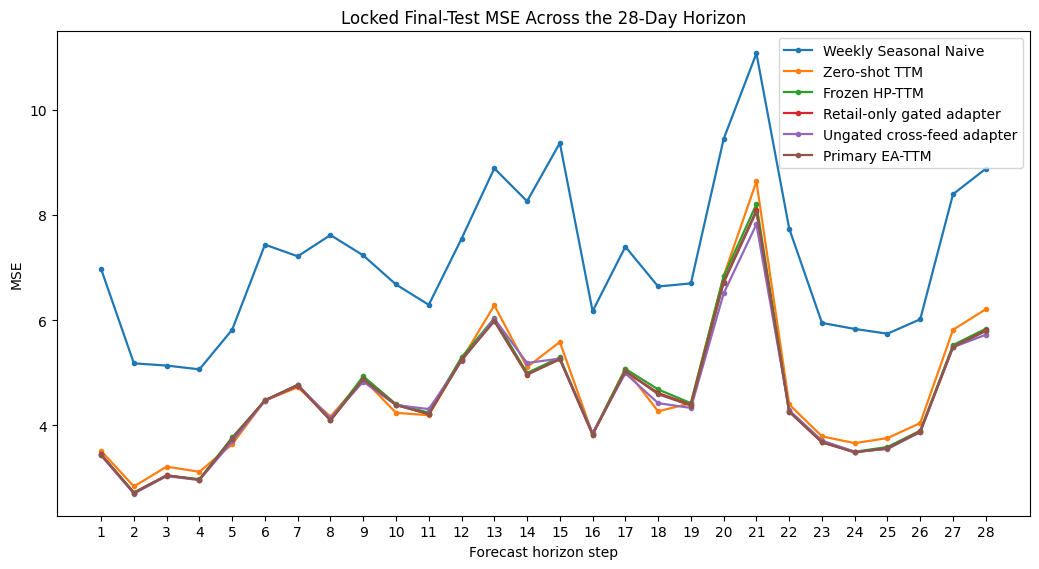

In [8]:
FIG01_PATH = RESULTS_FIGURE_DIR / "11B_FIG01_HORIZON_MSE_ALL_MODELS.png"

fig, ax = plt.subplots(figsize=(10.5, 5.8))

for model_name in model_arrays:
    model_frame = horizon_results.loc[
        horizon_results["model"] == model_name
    ]
    ax.plot(
        model_frame["horizon"],
        model_frame["mse"],
        marker="o",
        linewidth=1.6,
        markersize=3,
        label=model_name,
    )

ax.set_xlabel("Forecast horizon step")
ax.set_ylabel("MSE")
ax.set_title("Locked Final-Test MSE Across the 28-Day Horizon")
ax.set_xticks(horizon_index)
ax.legend()
fig.tight_layout()
fig.savefig(FIG01_PATH, dpi=220, bbox_inches="tight")
plt.show()

## Figure 2 — Horizon-wise overall MAE for all models

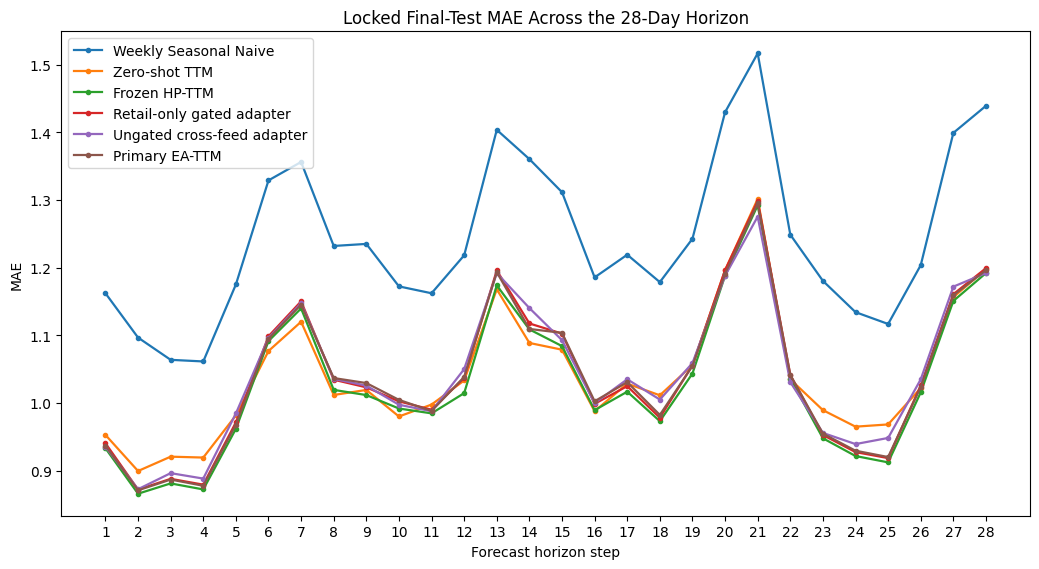

In [9]:
FIG02_PATH = RESULTS_FIGURE_DIR / "11B_FIG02_HORIZON_MAE_ALL_MODELS.png"

fig, ax = plt.subplots(figsize=(10.5, 5.8))

for model_name in model_arrays:
    model_frame = horizon_results.loc[
        horizon_results["model"] == model_name
    ]
    ax.plot(
        model_frame["horizon"],
        model_frame["mae"],
        marker="o",
        linewidth=1.6,
        markersize=3,
        label=model_name,
    )

ax.set_xlabel("Forecast horizon step")
ax.set_ylabel("MAE")
ax.set_title("Locked Final-Test MAE Across the 28-Day Horizon")
ax.set_xticks(horizon_index)
ax.legend()
fig.tight_layout()
fig.savefig(FIG02_PATH, dpi=220, bbox_inches="tight")
plt.show()

## Figure 3 — Horizon-wise overall WAPE for all models

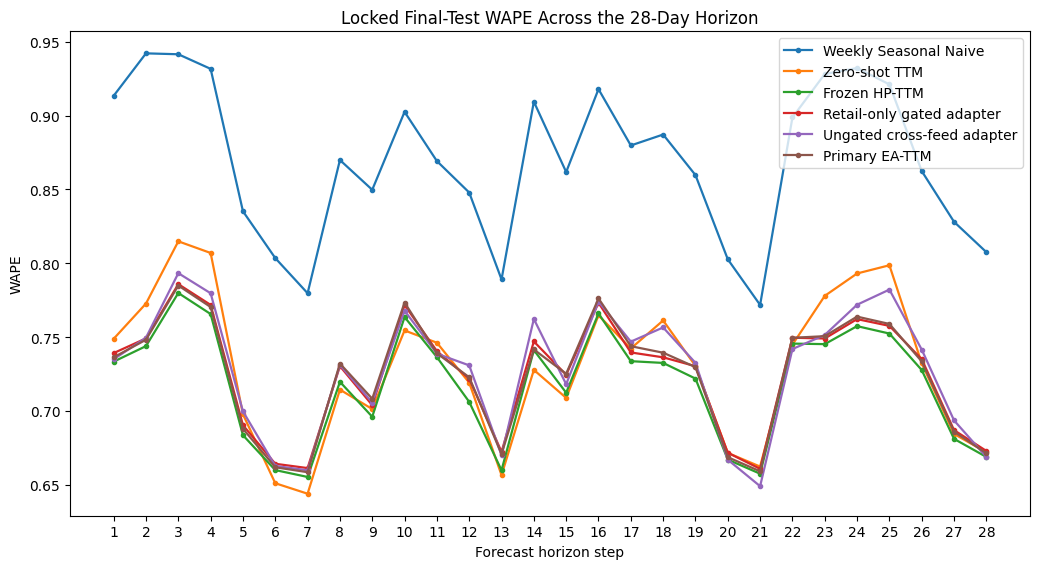

In [10]:
FIG03_PATH = RESULTS_FIGURE_DIR / "11B_FIG03_HORIZON_WAPE_ALL_MODELS.png"

fig, ax = plt.subplots(figsize=(10.5, 5.8))

for model_name in model_arrays:
    model_frame = horizon_results.loc[
        horizon_results["model"] == model_name
    ]
    ax.plot(
        model_frame["horizon"],
        model_frame["wape"],
        marker="o",
        linewidth=1.6,
        markersize=3,
        label=model_name,
    )

ax.set_xlabel("Forecast horizon step")
ax.set_ylabel("WAPE")
ax.set_title("Locked Final-Test WAPE Across the 28-Day Horizon")
ax.set_xticks(horizon_index)
ax.legend()
fig.tight_layout()
fig.savefig(FIG03_PATH, dpi=220, bbox_inches="tight")
plt.show()

## Figure 4 — Primary EA-TTM versus frozen HP-TTM: MSE improvement by horizon

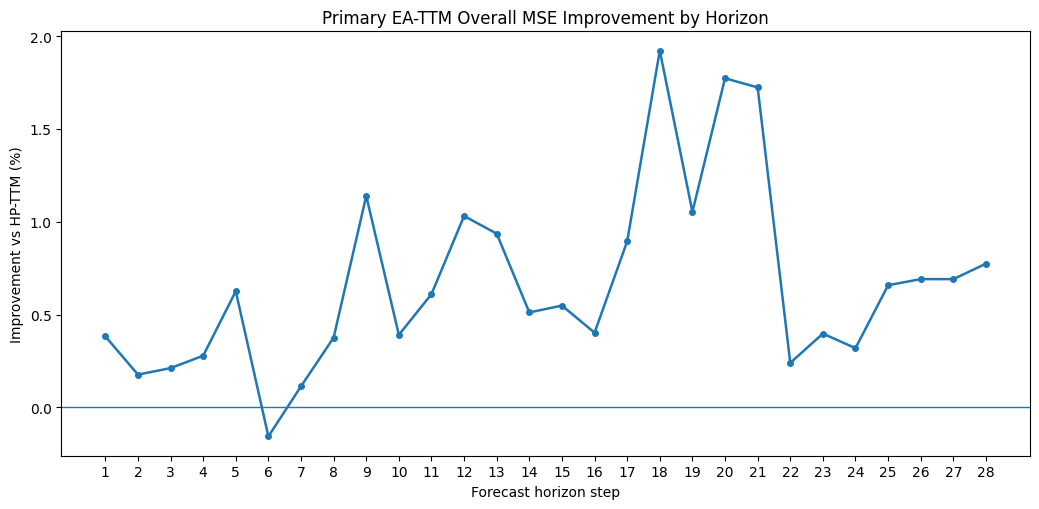

In [11]:
FIG04_PATH = RESULTS_FIGURE_DIR / "11B_FIG04_PRIMARY_VS_HP_MSE_IMPROVEMENT.png"

fig, ax = plt.subplots(figsize=(10.5, 5.2))

ax.plot(
    primary_vs_hp_horizon["horizon"],
    primary_vs_hp_horizon["mse_improvement_percent"],
    marker="o",
    linewidth=1.8,
    markersize=4,
)

ax.axhline(0.0, linewidth=1.0)
ax.set_xlabel("Forecast horizon step")
ax.set_ylabel("Improvement vs HP-TTM (%)")
ax.set_title("Primary EA-TTM Overall MSE Improvement by Horizon")
ax.set_xticks(horizon_index)

fig.tight_layout()
fig.savefig(FIG04_PATH, dpi=220, bbox_inches="tight")
plt.show()

## Figure 5 — Primary EA-TTM versus frozen HP-TTM: extreme-MSE improvement by horizon

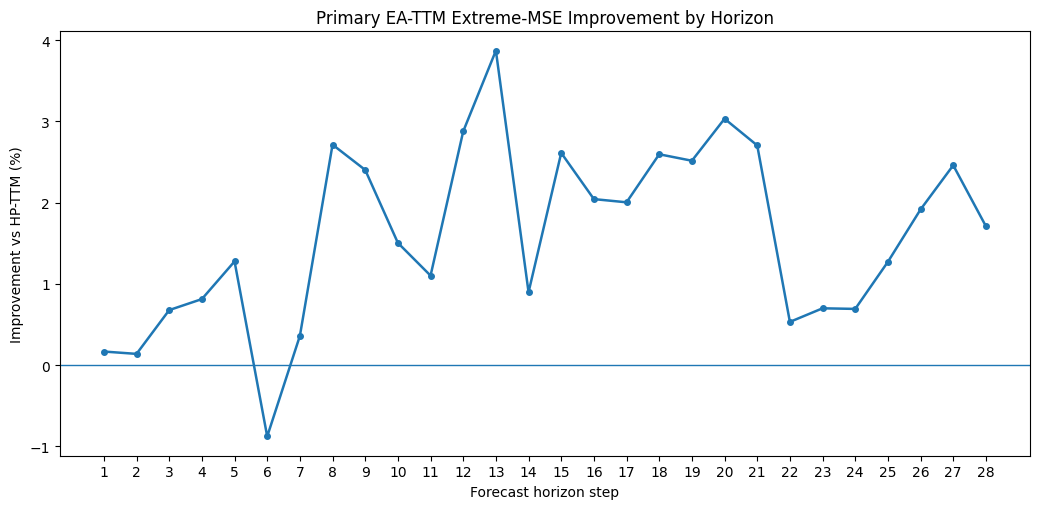

In [12]:
FIG05_PATH = RESULTS_FIGURE_DIR / "11B_FIG05_PRIMARY_VS_HP_EXTREME_MSE_IMPROVEMENT.png"

fig, ax = plt.subplots(figsize=(10.5, 5.2))

ax.plot(
    primary_vs_hp_horizon["horizon"],
    primary_vs_hp_horizon["extreme_mse_improvement_percent"],
    marker="o",
    linewidth=1.8,
    markersize=4,
)

ax.axhline(0.0, linewidth=1.0)
ax.set_xlabel("Forecast horizon step")
ax.set_ylabel("Improvement vs HP-TTM (%)")
ax.set_title("Primary EA-TTM Extreme-MSE Improvement by Horizon")
ax.set_xticks(horizon_index)

fig.tight_layout()
fig.savefig(FIG05_PATH, dpi=220, bbox_inches="tight")
plt.show()

## Figure 6 — Extreme prevalence by horizon

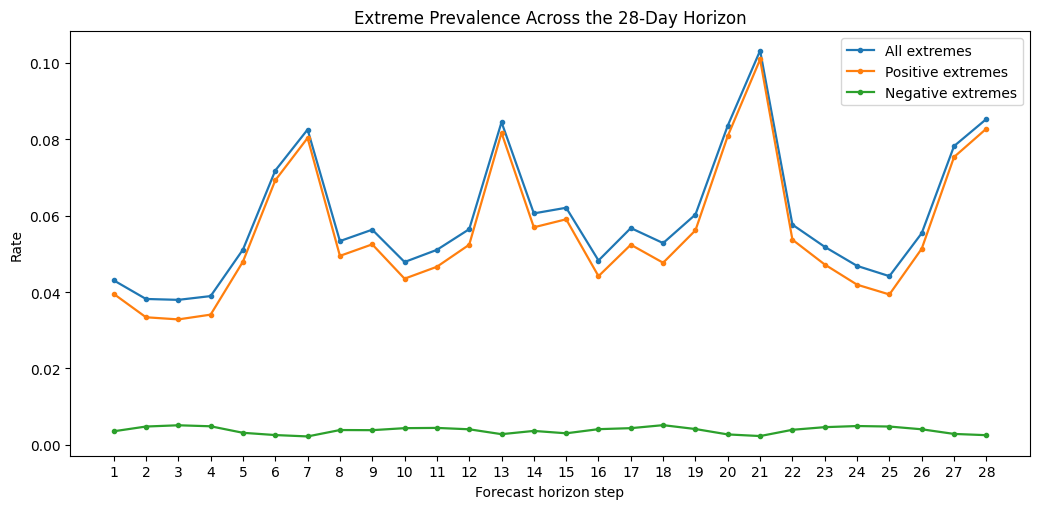

In [13]:
FIG06_PATH = RESULTS_FIGURE_DIR / "11B_FIG06_EXTREME_PREVALENCE_BY_HORIZON.png"

prevalence_frame = pd.DataFrame(
    {
        "horizon": horizon_index,
        "extreme_rate": extreme_count / SERIES_COUNT,
        "positive_extreme_rate": positive_extreme_count / SERIES_COUNT,
        "negative_extreme_rate": negative_extreme_count / SERIES_COUNT,
    }
)

fig, ax = plt.subplots(figsize=(10.5, 5.2))

ax.plot(
    prevalence_frame["horizon"],
    prevalence_frame["extreme_rate"],
    marker="o",
    linewidth=1.6,
    markersize=3,
    label="All extremes",
)

ax.plot(
    prevalence_frame["horizon"],
    prevalence_frame["positive_extreme_rate"],
    marker="o",
    linewidth=1.6,
    markersize=3,
    label="Positive extremes",
)

ax.plot(
    prevalence_frame["horizon"],
    prevalence_frame["negative_extreme_rate"],
    marker="o",
    linewidth=1.6,
    markersize=3,
    label="Negative extremes",
)

ax.set_xlabel("Forecast horizon step")
ax.set_ylabel("Rate")
ax.set_title("Extreme Prevalence Across the 28-Day Horizon")
ax.set_xticks(horizon_index)
ax.legend()

fig.tight_layout()
fig.savefig(FIG06_PATH, dpi=220, bbox_inches="tight")
plt.show()

## Optional focused figure — HP-TTM, primary EA-TTM, and ungated cross-feed only

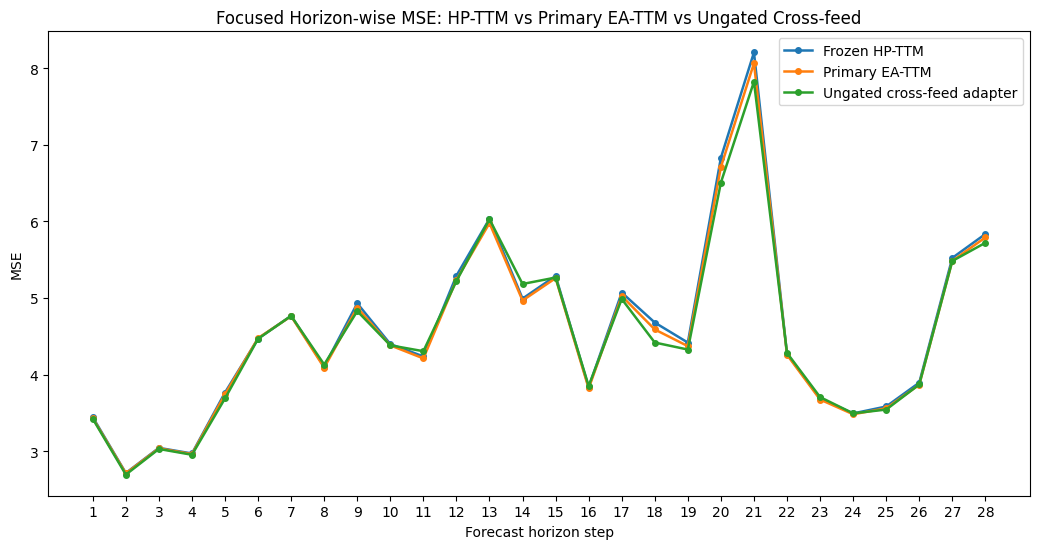

In [14]:
FIG07_PATH = RESULTS_FIGURE_DIR / "11B_FIG07_FOCUSED_MSE_HP_EA_UNGATED.png"

focused_models = [
    "Frozen HP-TTM",
    "Primary EA-TTM",
    "Ungated cross-feed adapter",
]

fig, ax = plt.subplots(figsize=(10.5, 5.6))

for model_name in focused_models:
    model_frame = horizon_results.loc[
        horizon_results["model"] == model_name
    ]
    ax.plot(
        model_frame["horizon"],
        model_frame["mse"],
        marker="o",
        linewidth=1.8,
        markersize=4,
        label=model_name,
    )

ax.set_xlabel("Forecast horizon step")
ax.set_ylabel("MSE")
ax.set_title("Focused Horizon-wise MSE: HP-TTM vs Primary EA-TTM vs Ungated Cross-feed")
ax.set_xticks(horizon_index)
ax.legend()

fig.tight_layout()
fig.savefig(FIG07_PATH, dpi=220, bbox_inches="tight")
plt.show()

## Narrative summary artifact

In [16]:
SUMMARY_PATH = PROJECT_ROOT / "results" / "11B_HORIZON_GRAPH_SUMMARY.md"

best_mse_horizon = int(
    primary_vs_hp_horizon.loc[
        primary_vs_hp_horizon["mse_improvement_percent"].idxmax(),
        "horizon",
    ]
)

worst_mse_horizon = int(
    primary_vs_hp_horizon.loc[
        primary_vs_hp_horizon["mse_improvement_percent"].idxmin(),
        "horizon",
    ]
)

best_extreme_horizon = int(
    primary_vs_hp_horizon.loc[
        primary_vs_hp_horizon["extreme_mse_improvement_percent"].idxmax(),
        "horizon",
    ]
)

worst_extreme_horizon = int(
    primary_vs_hp_horizon.loc[
        primary_vs_hp_horizon["extreme_mse_improvement_percent"].idxmin(),
        "horizon",
    ]
)

summary_lines = [
    "# EA-TTM Horizon Performance Summary",
    "",
    "This document summarizes the line-graph evidence created from the locked final-test outputs.",
    "",
    "## Key interpretation points",
    "",
    (
        "The horizon-wise plots show how error evolves from day 1 to day 28, "
        "rather than compressing the full horizon into a single aggregate metric."
    ),
    "",
    (
        f"The strongest overall MSE gain of the primary EA-TTM over frozen HP-TTM occurs at "
        f"horizon {best_mse_horizon}, while the weakest overall MSE gain occurs at horizon "
        f"{worst_mse_horizon}."
    ),
    "",
    (
        f"For extreme-only MSE, the strongest gain occurs at horizon {best_extreme_horizon}, "
        f"while the weakest gain occurs at horizon {worst_extreme_horizon}."
    ),
    "",
    (
        "These plots should be used in the report and defense to show whether the model's "
        "advantage is concentrated in early, middle, or late forecast steps."
    ),
    "",
    (
        "The extreme-prevalence line graph should be shown alongside the error curves so that "
        "the reader can interpret strong or weak horizon-specific gains in the context of how "
        "many extreme observations are actually present at each step."
    ),
]

SUMMARY_PATH.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)

943

## Reporting manifest

In [17]:
MANIFEST_PATH = METADATA_DIR / "11B_HORIZON_VISUALIZATION_MANIFEST.json"

manifest = {
    "status": "PHASE_11B_HORIZON_VISUALS_COMPLETE",
    "primary_model": PRIMARY_MODEL,
    "primary_epoch": PRIMARY_EPOCH,
    "post_test_tuning_permitted": False,
    "tables": {
        "horizon_metrics": str(HORIZON_RESULTS_PATH),
        "primary_vs_hp_horizon_comparison": str(PRIMARY_VS_HP_PATH),
    },
    "figures": {
        "all_models_mse": str(FIG01_PATH),
        "all_models_mae": str(FIG02_PATH),
        "all_models_wape": str(FIG03_PATH),
        "primary_vs_hp_mse_improvement": str(FIG04_PATH),
        "primary_vs_hp_extreme_mse_improvement": str(FIG05_PATH),
        "extreme_prevalence": str(FIG06_PATH),
        "focused_hp_ea_ungated_mse": str(FIG07_PATH),
    },
    "summary_document": str(SUMMARY_PATH),
}

MANIFEST_PATH.write_text(
    json.dumps(
        manifest,
        indent=2,
    ),
    encoding="utf-8",
)

1443

## Return block

The final block is the **only successful-run output that needs to be returned to ChatGPT**.

In [18]:
return_block = {
    "status": "PHASE_11B_HORIZON_VISUALS_COMPLETE",
    "primary_model": PRIMARY_MODEL,
    "primary_epoch": PRIMARY_EPOCH,
    "post_test_tuning_permitted": False,
    "artifacts": manifest,
}

print("PHASE 11B RETURN BLOCK")
print(
    json.dumps(
        return_block,
        indent=2,
    )
)

PHASE 11B RETURN BLOCK
{
  "status": "PHASE_11B_HORIZON_VISUALS_COMPLETE",
  "primary_model": "Phase 08 best-balanced EA-TTM",
  "primary_epoch": 15,
  "post_test_tuning_permitted": false,
  "artifacts": {
    "status": "PHASE_11B_HORIZON_VISUALS_COMPLETE",
    "primary_model": "Phase 08 best-balanced EA-TTM",
    "primary_epoch": 15,
    "post_test_tuning_permitted": false,
    "tables": {
      "horizon_metrics": "/content/drive/MyDrive/EA_TTM_RETAIL/results/tables/11B_FINAL_TEST_HORIZON_METRICS.csv",
      "primary_vs_hp_horizon_comparison": "/content/drive/MyDrive/EA_TTM_RETAIL/results/tables/11B_PRIMARY_VS_HP_HORIZON_COMPARISON.csv"
    },
    "figures": {
      "all_models_mse": "/content/drive/MyDrive/EA_TTM_RETAIL/results/figures/11B_FIG01_HORIZON_MSE_ALL_MODELS.png",
      "all_models_mae": "/content/drive/MyDrive/EA_TTM_RETAIL/results/figures/11B_FIG02_HORIZON_MAE_ALL_MODELS.png",
      "all_models_wape": "/content/drive/MyDrive/EA_TTM_RETAIL/results/figures/11B_FIG03_HORIZON